# 05 · Advanced models: XGBoost and LightGBM (grid search)

Both models are tuned with a **grid search** on the 24-month window (every combination in `param_spaces` is fit on train and scored on the validation set). The best parameters are then reused for every training window (6-30 months) and scored on test.

* Hyperparameters and the final "best" model are chosen on **validation only** (`SELECT_BY`); test is only reported.
* Validation and test metrics include sMAPE and MASE.
* The notebook ends with the best model by validation, with validation and test metrics side by side.

In [1]:
import glob, hashlib, json, os, platform, random, re, sys, time, warnings
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

import xgboost as xgb
import lightgbm as lgb

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterGrid

warnings.filterwarnings("ignore", message=".*eval_set.*")

In [2]:
# settings
DATA_DIR = "fe_outputs"
TARGET = "ClosePrice"
MIN_MONTHS, MAX_MONTHS = 6, 30
SEED = 42
STRICT_CHECKS = True
RUN_MANIFEST_FILE = "run_manifest.json"

random.seed(SEED)
np.random.seed(SEED)

run_log = []

def log_step(step, **info):
    run_log.append({"time": datetime.now().isoformat(timespec="seconds"), "step": step, **info})

# hash of the data files
def file_sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

def window_fingerprint(folder):
    parts = [f"{name}:{file_sha256(Path(folder) / name)}"
             for name in ("features_train.csv", "features_val.csv", "features_test.csv")]
    return hashlib.sha256("|".join(parts).encode()).hexdigest()

environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "cpu_count": os.cpu_count(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "lightgbm": lgb.__version__,
    "matplotlib": matplotlib.__version__,
}
log_step("environment", seed=SEED, data_dir=DATA_DIR, target=TARGET, **{k: v for k, v in environment.items() if k in ("python", "xgboost", "lightgbm")})


In [3]:
target = TARGET

def n_months(path):
    return int(re.search(r"train_(\d+)m", str(path)).group(1))

def metrics(y_true, y_pred, y_train):
    """Regression metrics. y_train is only used for the MASE scale."""
    y_true, y_pred, y_train = (np.asarray(a, dtype=float) for a in (y_true, y_pred, y_train))
    err = np.abs(y_pred - y_true)
    ape = err / y_true
    mse = mean_squared_error(y_true, y_pred)

    # sMAPE (%): symmetric, bounded 0-200%; |.| in the denominator so negative predictions are fine
    denom = np.abs(y_true) + np.abs(y_pred)
    smape = np.where(denom == 0, 0.0, 2 * err / np.where(denom == 0, 1, denom))

    # MASE: MAE divided by the train-set MAE of a naive benchmark. These are cross-sectional
    # sales (no "previous value"), so the naive forecast is "predict the train median price".
    # MASE < 1 means the model beats that naive benchmark; lower is better.
    naive_mae = np.mean(np.abs(y_train - np.median(y_train)))

    return {
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": ape.mean() * 100,
        "MdAPE_%": np.median(ape) * 100,
        "sMAPE_%": smape.mean() * 100,
        "MAE_$": err.mean(),
        "MSE_$2": mse,
        "RMSE_$": np.sqrt(mse),
        "MASE": err.mean() / naive_mae,
    }

split_dirs = sorted(
    (d for d in glob.glob(f"{DATA_DIR}/train_*m") if MIN_MONTHS <= n_months(d) <= MAX_MONTHS),
    key=n_months
)
print([n_months(d) for d in split_dirs])
if not split_dirs:
    raise FileNotFoundError(f"no train_<N>m folders in {DATA_DIR!r}")

# no dates as features
EXCLUDE_COLS = ["CloseDate"]
_warned = set()

def load_split(folder):
    train = pd.read_csv(f"{folder}/features_train.csv")
    val = pd.read_csv(f"{folder}/features_val.csv")
    test = pd.read_csv(f"{folder}/features_test.csv")

    banned = [c for c in train.columns
              if c in EXCLUDE_COLS or "date" in c.lower()]
    feats = (train.drop(columns=[target] + banned)
                  .select_dtypes(include="number").columns)
    dropped = [c for c in train.columns if c != target and c not in feats]
    if dropped and tuple(dropped) not in _warned:
        _warned.add(tuple(dropped))
        print("dropped:", dropped)

    X_tr, X_val, X_te = (
        df[feats].replace([np.inf, -np.inf], np.nan) for df in (train, val, test)
    )

    # nans -> train median
    med = X_tr.median()
    X_tr, X_val, X_te = X_tr.fillna(med), X_val.fillna(med), X_te.fillna(med)

    return X_tr, train[target], X_val, val[target], X_te, test[target]

[6, 9, 12, 15, 18, 21, 24, 27, 30]


In [4]:
# names that might be leaky
LEAKAGE_PATTERNS = [
    r"listprice", r"previouslistprice", r"currentprice", r"daysonmarket", r"(^|_)(dom|cdom)($|_)",
    r"pricechange", r"closeprice", r"closedate", r"purchasecontract", r"pendingtimestamp",
    r"offmarket", r"statuschange", r"contingent",
]

audit_rows, fingerprints, test_signature = [], {}, {}

for folder in split_dirs:
    months = n_months(folder)
    fingerprints[months] = window_fingerprint(folder)

    header = {s: pd.read_csv(f"{folder}/features_{s}.csv", nrows=0).columns.tolist()
              for s in ("train", "val", "test")}
    rows, tgt, dates = {}, {}, {}
    for s in ("train", "val", "test"):
        use = [c for c in (target, "CloseDate") if c in header[s]]
        part = pd.read_csv(f"{folder}/features_{s}.csv", usecols=use)
        rows[s] = len(part)
        tgt[s] = part[target] if target in part else pd.Series(dtype=float)
        if "CloseDate" in part:
            dates[s] = pd.to_datetime(part["CloseDate"], errors="coerce")

    problems = []
    if not (header["train"] == header["val"] == header["test"]):
        problems.append("columns differ across train/val/test")
    for s in ("train", "val", "test"):
        if target not in header[s]:
            problems.append(f"{s}: target column {target!r} missing")
        elif tgt[s].isna().any() or (tgt[s] <= 0).any():
            problems.append(f"{s}: missing or non-positive {target}")
    if len(dates) == 3 and not (dates["train"].max() < dates["val"].min()
                                and dates["val"].max() < dates["test"].min()):
        problems.append("splits are not in chronological order (train < val < test)")
    test_signature[months] = (rows["test"], round(float(tgt["test"].sum()), 2))

    used = [c for c in header["train"]
            if c != target and c not in EXCLUDE_COLS and "date" not in c.lower()]
    flagged = [c for c in used if any(re.search(p, c.lower()) for p in LEAKAGE_PATTERNS)]

    audit_rows.append({
        "n_months": months,
        "train_rows": rows["train"], "val_rows": rows["val"], "test_rows": rows["test"],
        "n_columns": len(header["train"]),
        "train_end": dates["train"].max().date() if dates else None,
        "val_start": dates["val"].min().date() if dates else None,
        "val_end": dates["val"].max().date() if dates else None,
        "test_start": dates["test"].min().date() if dates else None,
        "test_end": dates["test"].max().date() if dates else None,
        "fingerprint": fingerprints[months][:12],
        "leakage_name_flags": ", ".join(flagged),
        "problems": "; ".join(problems),
    })

data_audit = pd.DataFrame(audit_rows)

if len(set(test_signature.values())) > 1:
    msg = "test month differs across windows"
    data_audit["problems"] = data_audit["problems"].where(data_audit["problems"] == "", data_audit["problems"] + "; ") + msg

n_problems = int((data_audit["problems"] != "").sum())
n_flagged = int((data_audit["leakage_name_flags"] != "").sum())
log_step("input checks", windows=len(data_audit), windows_with_problems=n_problems,
         windows_with_leakage_name_flags=n_flagged)

# stop if something's wrong
if n_problems and STRICT_CHECKS:
    raise ValueError("input checks failed\n" + data_audit[["n_months", "problems"]].to_string())
if n_flagged:
    print("check these columns:")
    print(data_audit.loc[data_audit["leakage_name_flags"] != "", ["n_months", "leakage_name_flags"]].to_string())

data_audit


,n_months,train_rows,val_rows,test_rows,n_columns,train_end,val_start,val_end,test_start,test_end,fingerprint,leakage_name_flags,problems
0,6,72665,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,16791911c759,,
1,9,99110,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,e7d239b58850,,
2,12,132281,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,d7890f6096f6,,
3,15,167487,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,64c37067f718,,
4,18,201680,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,23e1b66147d5,,
5,21,229237,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,416c0676a7ab,,
6,24,263132,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,a450e1b8fed1,,
7,27,301391,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,7d6302b254e5,,
8,30,339518,11156,10472,83,2026-08-31,2026-09-01,2026-09-30,2026-10-01,2026-10-31,52ce695664cf,,


## Grid search

`ParameterGrid` fits every combination on the training set and scores it on the validation set (the data already has a fixed train/val split, so no cross-validation is needed). The grids are kept small on purpose: each fit takes about a minute, so the full search space from the earlier random search (1,000+ combinations per model) would take many hours. Parameters with a single value in the grid are fixed (taken from the earlier random search). The grid search only runs on the first run; after that the best parameters are reused (see `TUNING_MODE`).

In [5]:
# auto: reuse saved params, tune: redo the grid search, best_only: never tune
TUNING_MODE = "auto"

# Used for BOTH the grid search and the final best-model choice (validation only, never test)
SELECT_BY = "val_MdAPE_%"          # any val_* column from `results`
HIGHER_IS_BETTER = {"val_R2"}      # everything else: lower is better
sel_key = SELECT_BY.replace("val_", "", 1)
sign = 1 if SELECT_BY in HIGHER_IS_BETTER else -1    # so a bigger score is always better

BEST_PARAMS_FILE = "gbm_grid_best_params.json"
RESULTS_FILE = "gbm_results.csv"
TUNING_RESULTS_FILE = "gbm_grid_results.csv"

TUNE_MONTHS = 24     # the grid search runs on this window; the best params are reused for every window
MAX_TREES = 1500
EARLY_STOP = 100

# grid search space (32 fits per model). Single-value entries are fixed.
param_spaces = {
    "LightGBM": {
        "num_leaves": [63, 255],
        "learning_rate": [0.05, 0.1],
        "min_child_samples": [20, 50],
        "colsample_bytree": [0.7, 0.9],
        "log_target": [False, True],
        "subsample": [1.0],
        "reg_lambda": [1],
    },
    "XGBoost": {
        "max_depth": [6, 10],
        "learning_rate": [0.05, 0.1],
        "min_child_weight": [1, 5],
        "colsample_bytree": [0.7, 0.9],
        "log_target": [False, True],
        "subsample": [1.0],
        "reg_lambda": [10],
    },
}

# saved params are only reused if the data AND the search setup are unchanged
search_signature = hashlib.sha256(json.dumps(
    {"grid": param_spaces, "select_by": SELECT_BY, "max_trees": MAX_TREES,
     "early_stop": EARLY_STOP, "seed": SEED}, sort_keys=True).encode()).hexdigest()

if TUNING_MODE not in {"auto", "tune", "best_only"}:
    raise ValueError("TUNING_MODE should be auto, tune or best_only")
if TUNE_MONTHS not in fingerprints:
    raise ValueError(f"TUNE_MONTHS {TUNE_MONTHS} not in {sorted(fingerprints)}")

# predicts in dollars even with log target
class GBM:
    def __init__(self, model, log_target, best_iteration):
        self.model = model
        self.log_target = log_target
        self.best_iteration = best_iteration

    def predict(self, X):
        pred = self.model.predict(X)
        return np.exp(pred) if self.log_target else pred

def fit_gbm(name, params, X_tr, y_tr, X_val, y_val):
    params = dict(params)
    log_target = params.pop("log_target")
    y_fit, y_eval = (np.log(y_tr), np.log(y_val)) if log_target else (y_tr, y_val)

    if name == "LightGBM":
        model = lgb.LGBMRegressor(
            n_estimators=MAX_TREES, subsample_freq=1,
            random_state=SEED, n_jobs=-1, verbose=-1, **params
        )
        model.fit(X_tr, y_fit, eval_set=[(X_val, y_eval)],
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
        best_iter = model.best_iteration_
    else:
        model = xgb.XGBRegressor(
            n_estimators=MAX_TREES, tree_method="hist",
            early_stopping_rounds=EARLY_STOP,
            random_state=SEED, n_jobs=-1, **params
        )
        model.fit(X_tr, y_fit, eval_set=[(X_val, y_eval)], verbose=False)
        best_iter = model.best_iteration + 1

    return GBM(model, log_target, best_iter)

In [6]:
saved_params, saved_meta = {}, {}
if TUNING_MODE != "tune" and Path(BEST_PARAMS_FILE).exists():
    saved_params = json.loads(Path(BEST_PARAMS_FILE).read_text())
    saved_meta = saved_params.pop("_meta", {})
    if (saved_meta.get("data_fingerprint") != fingerprints[TUNE_MONTHS]
            or saved_meta.get("search_signature") != search_signature):
        msg = f"{BEST_PARAMS_FILE} is from different data or a different search setup."
        if TUNING_MODE == "best_only":
            raise ValueError(msg)
        print(msg, "re-tuning")
        saved_params, saved_meta = {}, {}

meta_now = {
    "data_fingerprint": fingerprints[TUNE_MONTHS], "tune_months": TUNE_MONTHS, "seed": SEED,
    "search": "grid", "grid_sizes": {n: len(ParameterGrid(g)) for n, g in param_spaces.items()},
    "search_signature": search_signature, "max_trees": MAX_TREES, "early_stop": EARLY_STOP,
    "selection_metric": SELECT_BY, "created": datetime.now().isoformat(timespec="seconds"),
    "xgboost": xgb.__version__, "lightgbm": lgb.__version__,
}
tuned_now = []

tuning_rows = []

X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(f"{DATA_DIR}/train_{TUNE_MONTHS}m")

for name in param_spaces:
    key = f"{TUNE_MONTHS}m_{name}"

    if TUNING_MODE == "best_only" and key not in saved_params:
        raise FileNotFoundError(
            f"no saved params for {key}"
        )
    if TUNING_MODE != "tune" and key in saved_params:
        print(f"{name}: saved params {saved_params[key]}")
        continue

    # grid search: fit every combination on train, pick the best on validation
    best_score = -np.inf
    grid = list(ParameterGrid(param_spaces[name]))
    for i, params in enumerate(grid, 1):
        params = dict(params)
        t0 = time.time()
        candidate = fit_gbm(name, params, X_tr, y_tr, X_val, y_val)
        scores = metrics(y_val, candidate.predict(X_val), y_tr)
        tuning_rows.append({
            "model": name,
            "n_train_months": TUNE_MONTHS,
            "params": str(params),
            "log_target": params["log_target"],
            "best_iteration": candidate.best_iteration,
            **{f"val_{k}": v for k, v in scores.items()},
            "fit_seconds": time.time() - t0,
        })
        print(f"{name} {i}/{len(grid)}  val MdAPE {scores['MdAPE_%']:.3f}  R2 {scores['R2']:.4f}  "
              f"trees {candidate.best_iteration}  {time.time() - t0:.0f}s")
        if sign * scores[sel_key] > best_score:
            best_score, best_val, best_params = sign * scores[sel_key], scores[sel_key], params
        del candidate

    saved_params[key] = best_params
    tuned_now.append(name)
    Path(BEST_PARAMS_FILE).write_text(json.dumps({**saved_params, "_meta": meta_now}, indent=2))
    print(f"{name} best {SELECT_BY}: {best_val:.3f} {best_params}\n")

if tuning_rows:
    new_tuning = pd.DataFrame(tuning_rows)
    if TUNING_MODE == "auto" and Path(TUNING_RESULTS_FILE).exists():
        old = pd.read_csv(TUNING_RESULTS_FILE)
        old = old[~old["model"].isin(new_tuning["model"].unique())]
        new_tuning = pd.concat([old, new_tuning], ignore_index=True)
    new_tuning.to_csv(TUNING_RESULTS_FILE, index=False)

tuning_results = pd.read_csv(TUNING_RESULTS_FILE) if Path(TUNING_RESULTS_FILE).exists() else pd.DataFrame()
log_step("hyperparameters", tune_months=TUNE_MONTHS, tuned_now=tuned_now or "none",
         **{f"best_{n}": saved_params[f"{TUNE_MONTHS}m_{n}"] for n in param_spaces})

dropped: ['CloseDate']
LightGBM: saved params {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'log_target': True, 'min_child_samples': 50, 'num_leaves': 255, 'reg_lambda': 1, 'subsample': 1.0}
XGBoost: saved params {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'log_target': True, 'max_depth': 10, 'min_child_weight': 1, 'reg_lambda': 10, 'subsample': 1.0}


In [7]:
# skip windows we already did
REUSE_SAVED_RESULTS = True

store = {}
if REUSE_SAVED_RESULTS and Path(RESULTS_FILE).exists():
    store = {(r["model"], r["n_train_months"]): r
             for r in pd.read_csv(RESULTS_FILE).to_dict("records")}

fitted_now, reused_now = [], []
best_models = {}

for folder in split_dirs:
    months = n_months(folder)

    todo = []
    for name in param_spaces:
        best_params = saved_params[f"{TUNE_MONTHS}m_{name}"]
        old = store.get((name, months))
        # saved rows from before sMAPE/MASE were added have no such columns, so they are refit
        complete = old is not None and all(pd.notna(old.get(c)) for c in ("train_R2", "val_MASE", "test_MASE"))
        if complete and months != TUNE_MONTHS and old["best_params"] == str(best_params) \
                and old.get("data_fingerprint") == fingerprints[months]:
            print(f"{months}m {name}: reused")
            reused_now.append((name, months))
        else:
            todo.append(name)
    if not todo:
        continue

    X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(folder)

    for name in todo:
        best_params = saved_params[f"{TUNE_MONTHS}m_{name}"]

        t0 = time.time()
        model = fit_gbm(name, best_params, X_tr, y_tr, X_val, y_val)
        fit_seconds = time.time() - t0
        val_pred = model.predict(X_val)
        pred = model.predict(X_te)

        if months == TUNE_MONTHS:
            best_models[name] = model

        store[(name, months)] = {
            "model": name,
            "n_train_months": months,
            "n_features": X_tr.shape[1],
            "n_train_rows": len(X_tr),
            "data_fingerprint": fingerprints[months],
            "seed": SEED,
            "best_params": str(best_params),
            "best_iteration": model.best_iteration,
            "fit_seconds": fit_seconds,
            "train_R2": r2_score(y_tr, model.predict(X_tr)),
            **{f"val_{k}": v for k, v in metrics(y_val, val_pred, y_tr).items()},
            "val_neg_preds": int((val_pred <= 0).sum()),
            **{f"test_{k}": v for k, v in metrics(y_te, pred, y_tr).items()},
            "neg_preds": int((pred <= 0).sum()),
        }
        fitted_now.append((name, months))
        row = store[(name, months)]
        print(f"{months}m {name}: test R2 {row['test_R2']:.4f}, MdAPE {row['test_MdAPE_%']:.3f}")
        pd.DataFrame(store.values()).to_csv(RESULTS_FILE, index=False)

results = pd.DataFrame(
    [store[(name, n_months(f))] for f in split_dirs for name in param_spaces]
)
log_step("train windows", fitted=len(fitted_now), reused=len(reused_now), results_file=RESULTS_FILE)
display(results.drop(columns=["best_params", "data_fingerprint"]))

6m LightGBM: reused
6m XGBoost: reused
9m LightGBM: reused
9m XGBoost: reused
12m LightGBM: reused
12m XGBoost: reused
15m LightGBM: reused
15m XGBoost: reused
18m LightGBM: reused
18m XGBoost: reused
21m LightGBM: reused
21m XGBoost: reused
24m LightGBM: test R2 0.8753, MdAPE 7.455
24m XGBoost: test R2 0.8750, MdAPE 7.376
27m LightGBM: reused
27m XGBoost: reused
30m LightGBM: reused
30m XGBoost: reused


,model,n_train_months,n_features,n_train_rows,seed,best_iteration,fit_seconds,train_R2,val_R2,val_MAPE_%,...,val_neg_preds,test_R2,test_MAPE_%,test_MdAPE_%,test_sMAPE_%,test_MAE_$,test_MSE_$2,test_RMSE_$,test_MASE,neg_preds
0,LightGBM,6,81,72665,42,721,36.285937,0.969764,0.843158,12.083018,...,0,0.845489,12.702247,7.872652,11.880183,183393.722531,2.717615e+11,521307.480264,0.275922,0
1,XGBoost,6,81,72665,42,983,48.647891,0.987103,0.836102,12.081462,...,0,0.842716,12.662895,7.923086,11.832404,182197.733766,2.766393e+11,525965.072598,0.274123,0
2,LightGBM,9,81,99110,42,729,51.744284,0.963075,0.845801,11.871575,...,0,0.852714,12.352284,7.789228,11.667781,178388.374684,2.590543e+11,508973.767906,0.273289,0
3,XGBoost,9,81,99110,42,1411,71.791415,0.990077,0.840687,11.807879,...,0,0.850258,12.349300,7.655515,11.593438,177927.762239,2.633729e+11,513198.659574,0.272583,0
4,LightGBM,12,81,132281,42,894,60.594343,0.963013,0.852325,11.703377,...,0,0.866618,12.267092,7.574860,11.511724,175336.588692,2.345989e+11,484354.084941,0.271862,0
5,XGBoost,12,81,132281,42,1169,69.933286,0.980845,0.841821,11.672659,...,0,0.860349,12.242368,7.528522,11.480998,174546.296800,2.456255e+11,495606.205395,0.270636,0
6,LightGBM,15,81,167487,42,940,67.969708,0.959815,0.854817,11.557680,...,0,0.863104,12.144277,7.559572,11.406784,173545.473254,2.407795e+11,490692.832758,0.269701,0
7,XGBoost,15,81,167487,42,1363,84.080163,0.982497,0.847445,11.534150,...,0,0.859868,12.091604,7.543257,11.340480,173158.154447,2.464719e+11,496459.396417,0.269099,0
8,LightGBM,18,81,201680,42,1232,87.642341,0.966412,0.850008,11.414838,...,0,0.869583,12.022790,7.453484,11.305589,170830.989202,2.293841e+11,478940.564505,0.265352,0
9,XGBoost,18,81,201680,42,1466,95.013527,0.981422,0.844258,11.472780,...,0,0.860418,11.977366,7.446839,11.259892,172051.644208,2.455041e+11,495483.715283,0.267248,0


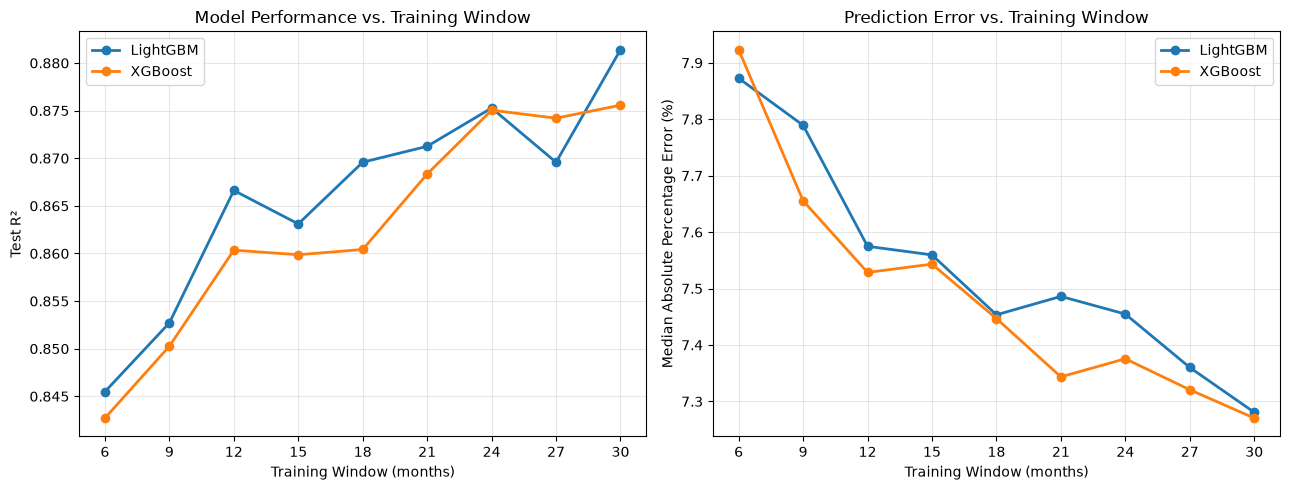

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in results.groupby("model"):

    group = group.sort_values("n_train_months")

    axes[0].plot(
        group["n_train_months"],
        group["test_R2"],
        marker="o",
        linewidth=2,
        label=name
    )

    axes[1].plot(
        group["n_train_months"],
        group["test_MdAPE_%"],
        marker="o",
        linewidth=2,
        label=name
    )

axes[0].set(
    xlabel="Training Window (months)",
    ylabel="Test R²",
    title="Model Performance vs. Training Window"
)

axes[1].set(
    xlabel="Training Window (months)",
    ylabel="Median Absolute Percentage Error (%)",
    title="Prediction Error vs. Training Window"
)

for ax in axes:
    ax.set_xticks(sorted(results["n_train_months"].unique()))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


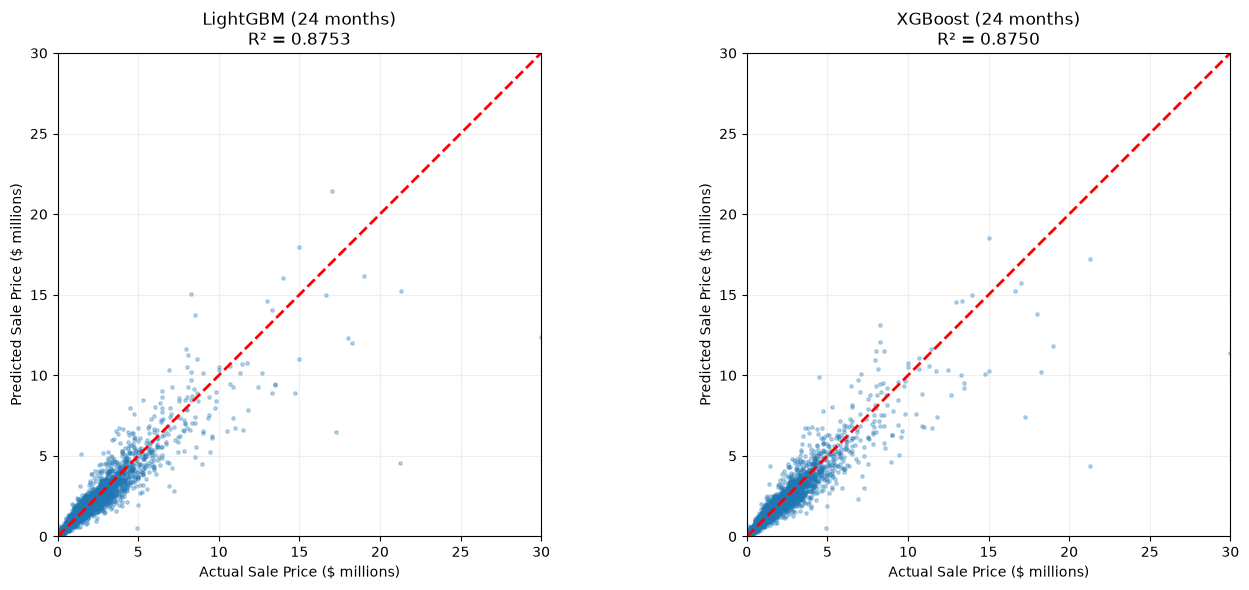

R2     MAPE_%   MdAPE_%    sMAPE_%          MAE_$  \
LightGBM validation  0.850427  11.276288  7.159269  10.647303  165077.959074   
         test        0.875274  11.860226  7.454784  11.154316  168372.358607   
XGBoost  validation  0.849002  11.288241  7.093679  10.637035  164912.336179   
         test        0.875045  11.808382  7.375572  11.111716  167223.585952   

                           MSE_$2         RMSE_$      MASE  
LightGBM validation  2.910261e+11  539468.359019  0.256813  
         test        2.193749e+11  468374.690050  0.261938  
XGBoost  validation  2.937991e+11  542032.363966  0.256556  
         test        2.197771e+11  468803.930328  0.260151

In [9]:
MONTHS = TUNE_MONTHS

folder = f"{DATA_DIR}/train_{MONTHS}m"

X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(folder)
models = best_models

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, models.items()):

    pred = model.predict(X_te)

    actual_millions = y_te / 1_000_000
    predicted_millions = pred / 1_000_000

    ax.scatter(
        actual_millions,
        predicted_millions,
        s=6,
        alpha=0.3
    )

    limit = max(
        actual_millions.max(),
        predicted_millions.max()
    )

    ax.plot(
        [0, limit],
        [0, limit],
        "r--",
        linewidth=2,
    )

    ax.set_xlabel("Actual Sale Price ($ millions)")
    ax.set_ylabel("Predicted Sale Price ($ millions)")

    ax.set_title(
        f"{name} ({MONTHS} months)\n"
        f"R² = {r2_score(y_te, pred):.4f}"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_aspect("equal", adjustable="box")

    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

pd.concat({
    name: pd.DataFrame({
        "validation": metrics(y_val, model.predict(X_val), y_tr),
        "test": metrics(y_te, model.predict(X_te), y_tr),
    }).T
    for name, model in models.items()
})

## Comparison

In [10]:
frames = [results]
for label, path in [("baseline", "baseline_results.csv"), ("tree/forest", "tree_forest_results.csv")]:
    if Path(path).exists():
        frames.insert(0, pd.read_csv(path))
    else:
        print(f"{path} not found, skipping")

keep = (["model", "n_train_months", "n_train_rows"]
        + [c for c in results.columns if c.startswith(("val_", "test_"))] + ["neg_preds"])
all_results = pd.concat(frames, ignore_index=True).reindex(columns=keep)

order = [m for m in ["LinearRegression", "DecisionTree", "RandomForest", "XGBoost", "LightGBM"]
         if m in set(all_results["model"])]
cols = ["val_R2", "val_MdAPE_%", "test_R2", "test_MAPE_%", "test_MdAPE_%", "test_sMAPE_%", "test_MAE_$", "test_RMSE_$", "test_MASE", "neg_preds"]
cols = list(dict.fromkeys(cols + [SELECT_BY]))   # selection column must be present

comparison = (all_results[all_results["n_train_months"] == TUNE_MONTHS]
              .set_index("model")[cols].loc[order])

for ref, label in [("LinearRegression", "LR"), ("RandomForest", "RF")]:
    if ref in comparison.index:
        comparison[f"MdAPE_gain_vs_{label}_%"] = (1 - comparison["test_MdAPE_%"] / comparison.loc[ref, "test_MdAPE_%"]) * 100
comparison["neg_preds"] = comparison["neg_preds"].astype("Int64")

selected = comparison[SELECT_BY].idxmax() if SELECT_BY in HIGHER_IS_BETTER else comparison[SELECT_BY].idxmin()
log_step("model comparison", window_months=TUNE_MONTHS, models=len(comparison), selected_by=SELECT_BY,
         selected_model=selected, test_R2=round(float(comparison.loc[selected, "test_R2"]), 4),
         test_MdAPE_pct=round(float(comparison.loc[selected, "test_MdAPE_%"]), 3))
comparison.round(4)

,val_R2,val_MdAPE_%,test_R2,test_MAPE_%,test_MdAPE_%,test_sMAPE_%,test_MAE_$,test_RMSE_$,test_MASE,neg_preds,MdAPE_gain_vs_LR_%,MdAPE_gain_vs_RF_%
model,,,,,,,,,,,,
LinearRegression,0.7894,13.4502,0.7878,19.9738,14.1527,18.3202,252753.4028,610942.6538,0.3932,0,0.0000,-75.5082
DecisionTree,0.5339,9.5897,0.6937,16.9955,9.8613,15.2520,250216.9772,733932.1694,0.3893,0,30.3224,-22.2899
RandomForest,0.8482,7.8259,0.8514,13.5091,8.0638,12.2557,187661.0172,511185.7067,0.2919,0,43.0226,0.0000
XGBoost,0.8490,7.0937,0.8750,11.8084,7.3756,11.1117,167223.5860,468803.9303,0.2602,0,47.8858,8.5353
LightGBM,0.8504,7.1593,0.8753,11.8602,7.4548,11.1543,168372.3586,468374.6901,0.2619,0,47.3261,7.5529


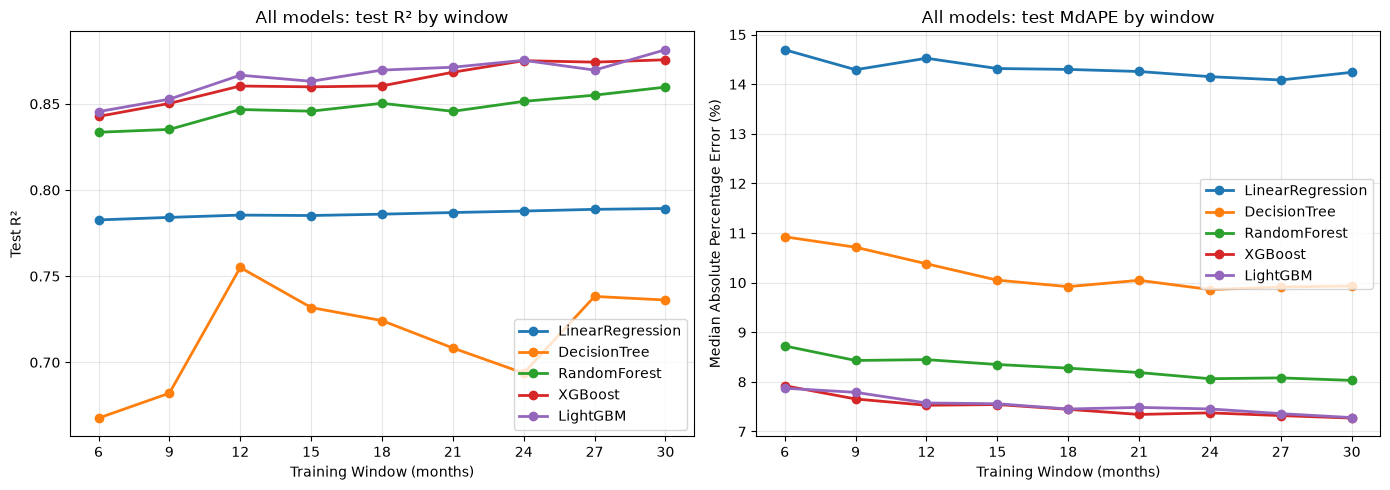

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in order:
    g = all_results[all_results["model"] == name].sort_values("n_train_months")
    axes[0].plot(g["n_train_months"], g["test_R2"], marker="o", linewidth=2, label=name)
    axes[1].plot(g["n_train_months"], g["test_MdAPE_%"], marker="o", linewidth=2, label=name)

axes[0].set(xlabel="Training Window (months)", ylabel="Test R²", title="All models: test R² by window")
axes[1].set(xlabel="Training Window (months)", ylabel="Median Absolute Percentage Error (%)",
            title="All models: test MdAPE by window")
for ax in axes:
    ax.set_xticks(sorted(all_results["n_train_months"].unique()))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [12]:
lr = LinearRegression().fit(X_tr, y_tr)
ape = {"LinearRegression": np.abs(lr.predict(X_te) - y_te).to_numpy() / y_te.to_numpy()}
for name, model in models.items():
    ape[name] = np.abs(model.predict(X_te) - y_te).to_numpy() / y_te.to_numpy()

# resample the test set to see if the gap is real
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(y_te), size=(1000, len(y_te)))

def paired_diff(a, b):
    d = np.array([np.median(ape[a][i]) - np.median(ape[b][i]) for i in idx]) * 100
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {"model_a": a, "model_b": b, "MdAPE_diff_pp": d.mean(), "ci_low": lo, "ci_high": hi,
            "excludes_zero": bool(lo > 0 or hi < 0)}

pd.DataFrame([paired_diff("LightGBM", "LinearRegression"),
              paired_diff("XGBoost", "LinearRegression"),
              paired_diff("LightGBM", "XGBoost")]).round(3)


,model_a,model_b,MdAPE_diff_pp,ci_low,ci_high,excludes_zero
0,LightGBM,LinearRegression,-6.702,-7.001,-6.396,True
1,XGBoost,LinearRegression,-6.768,-7.065,-6.452,True
2,LightGBM,XGBoost,0.066,-0.066,0.200,False


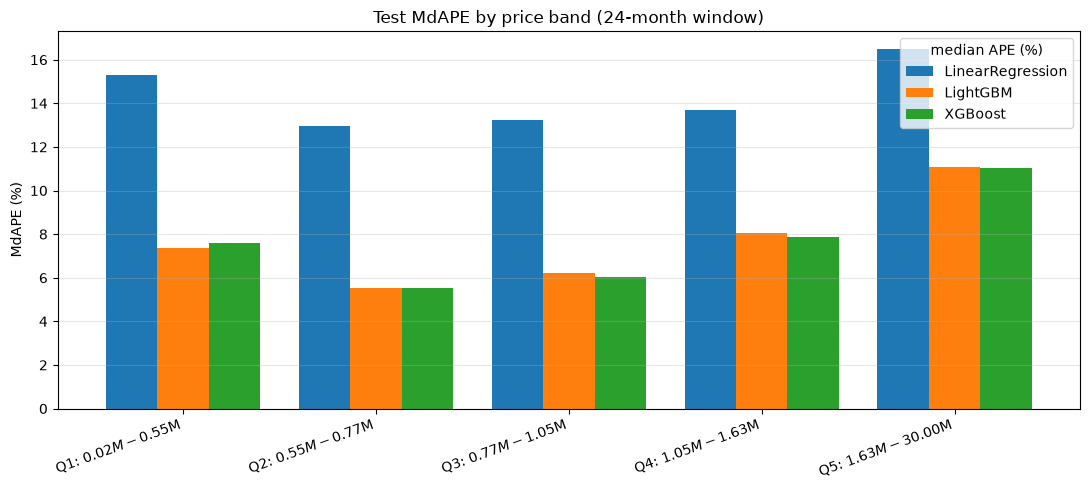

median APE (%),LinearRegression,LightGBM,XGBoost
Q1: $0.02M-$0.55M,15.30,7.36,7.59
Q2: $0.55M-$0.77M,12.95,5.51,5.55
Q3: $0.77M-$1.05M,13.24,6.20,6.02
Q4: $1.05M-$1.63M,13.70,8.07,7.87
Q5: $1.63M-$30.00M,16.48,11.08,11.05


In [13]:
edges = np.quantile(y_te, np.linspace(0, 1, 6))
band = np.clip(np.searchsorted(edges, y_te.to_numpy(), side="right") - 1, 0, 4)
band_labels = [f"Q{i+1}: ${edges[i]/1e6:.2f}M-${edges[i+1]/1e6:.2f}M" for i in range(5)]

band_table = pd.DataFrame({
    name: pd.Series(a * 100).groupby(band).median() for name, a in ape.items()
})
band_table.index = band_labels
band_table.columns.name = "median APE (%)"

ax = band_table.plot.bar(figsize=(11, 5), width=0.8)
ax.set(ylabel="MdAPE (%)", title=f"Test MdAPE by price band ({MONTHS}-month window)")
ax.grid(alpha=0.3, axis="y")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

band_table.round(2)


## Feature importance

In [14]:
gain = {
    "LightGBM": pd.Series(
        models["LightGBM"].model.booster_.feature_importance(importance_type="gain"),
        index=X_tr.columns),
    "XGBoost": pd.Series(
        models["XGBoost"].model.get_booster().get_score(importance_type="gain")
    ).reindex(X_tr.columns).fillna(0),
}

importances = pd.DataFrame(gain)
importances = (importances / importances.sum()).sort_values("LightGBM", ascending=False)

importances.head(15)


,LightGBM,XGBoost
est_value_area,0.691574,0.512020
log_est_value_area,0.096333,0.310775
PostalCode_cat_te,0.093737,0.039292
log_living_area,0.015783,0.001020
City_te,0.009360,0.009454
MLSAreaMajor_te,0.006477,0.005892
zip_med_ppsf_12m,0.005467,0.001949
living_to_lot_ratio,0.005233,0.001930
LotSizeSquareFeet,0.004966,0.002002
Longitude,0.004955,0.002139


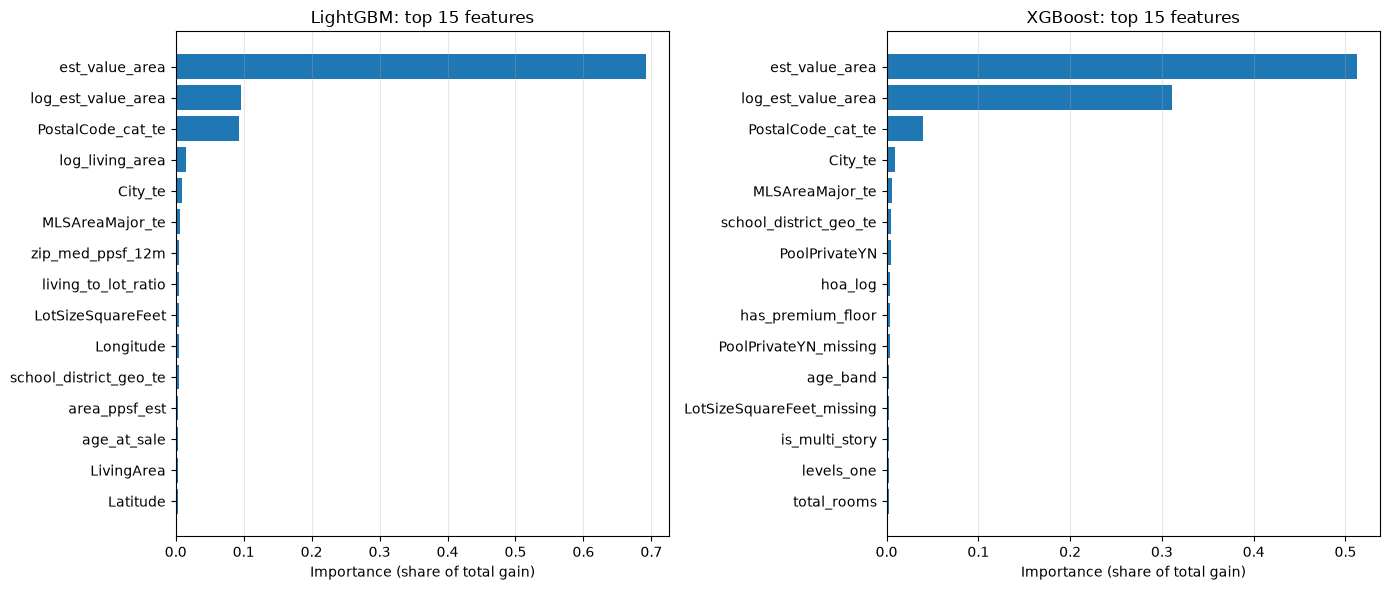

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name in zip(axes, importances.columns):
    top = importances[name].sort_values(ascending=False).head(15).iloc[::-1]
    ax.barh(top.index, top.values, color="tab:blue")
    ax.set(xlabel="Importance (share of total gain)", title=f"{name}: top 15 features")
    ax.grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()


## Final best models

Each model with the training window that had the best validation score (`SELECT_BY`), using the parameters from the grid search. Selection uses validation only; test is reported, never used to choose. Validation and test metrics are shown side by side, and the best model overall is listed first.


In [16]:
def pick_best(df):
    idx = df[SELECT_BY].idxmax() if SELECT_BY in HIGHER_IS_BETTER else df[SELECT_BY].idxmin()
    return results.loc[idx]

best_per_model = {m: pick_best(g) for m, g in results.groupby("model")}
best_per_model = dict(sorted(best_per_model.items(), key=lambda kv: sign * kv[1][SELECT_BY], reverse=True))

# (key in `results`, label, number format)
ROWS = [("R2", "R²", ",.4f"), ("MAPE_%", "MAPE (%)", ",.2f"), ("MdAPE_%", "MdAPE (%)", ",.2f"),
        ("sMAPE_%", "sMAPE (%)", ",.2f"), ("MAE_$", "MAE ($)", ",.0f"), ("MSE_$2", "MSE ($²)", ",.3e"),
        ("RMSE_$", "RMSE ($)", ",.0f"), ("MASE", "MASE", ",.4f")]

for rank, (m, r) in enumerate(best_per_model.items()):
    print("=" * 66)
    print(f"{m.upper()}" + ("  <-- BEST MODEL (best validation)" if rank == 0 else ""))
    print("=" * 66)
    print(f"Data:            {DATA_DIR} ({int(r['n_features'])} features)")
    print(f"Training window: {int(r['n_train_months'])} months ({int(r['n_train_rows']):,} train rows)")
    print(f"Hyperparameters: {r['best_params']}")
    print(f"                 (grid search on the {TUNE_MONTHS}-month window)")
    print(f"Trees used:      {int(r['best_iteration'])} (early stopping on validation)")
    print(f"Selected by:     best {SELECT_BY} = {r[SELECT_BY]:,.4f}")
    print(f"Train R²:        {r['train_R2']:.4f}")
    print("-" * 66)
    print(f"{'Metric':<14}{'Validation':>24}{'Test':>24}")
    print("-" * 66)
    for key, label, fmt in ROWS:
        print(f"{label:<14}{format(r['val_' + key], fmt):>24}{format(r['test_' + key], fmt):>24}")
    print(f"{'Negative preds':<14}{int(r['val_neg_preds']):>24,}{int(r['neg_preds']):>24,}")
    print()
print("MASE < 1 = beats predicting the train median price. Lower is better for every metric except R².")
if any(int(r["n_train_months"]) != TUNE_MONTHS for r in best_per_model.values()):
    print(f"Note: the plots, importances and significance tests above use the {TUNE_MONTHS}-month window "
          "the parameters were tuned on, which is not the best-validation window for every model.")

final_metrics = pd.DataFrame({
    f"{m} | {split}": {**{label: r[pre + k] for k, label, _ in ROWS},
                        "Negative preds": r["val_neg_preds" if pre == "val_" else "neg_preds"]}
    for m, r in best_per_model.items()
    for split, pre in (("validation", "val_"), ("test", "test_"))
})
final_metrics.to_csv("gbm_best_models_metrics.csv")
final_metrics

LIGHTGBM  <-- BEST MODEL (best validation)
Data:            fe_outputs (81 features)
Training window: 30 months (339,518 train rows)
Hyperparameters: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'log_target': True, 'min_child_samples': 50, 'num_leaves': 255, 'reg_lambda': 1, 'subsample': 1.0}
                 (grid search on the 24-month window)
Trees used:      1499 (early stopping on validation)
Selected by:     best val_MdAPE_% = 7.0678
Train R²:        0.9632
------------------------------------------------------------------
Metric                      Validation                    Test
------------------------------------------------------------------
R²                              0.8586                  0.8814
MAPE (%)                         11.12                   11.77
MdAPE (%)                         7.07                    7.28
sMAPE (%)                        10.55                   11.08
MAE ($)                        162,238                 166,768
MSE ($²)        

,LightGBM | validation,LightGBM | test,XGBoost | validation,XGBoost | test
R²,8.585534e-01,8.813917e-01,8.546827e-01,8.755698e-01
MAPE (%),1.111848e+01,1.176647e+01,1.116843e+01,1.173712e+01
MdAPE (%),7.067761e+00,7.280685e+00,7.075260e+00,7.270482e+00
sMAPE (%),1.055198e+01,1.108047e+01,1.056414e+01,1.104020e+01
MAE ($),1.622384e+05,1.667676e+05,1.638081e+05,1.662526e+05
MSE ($²),2.752154e+11,2.086141e+11,2.827467e+11,2.188541e+11
RMSE ($),5.246097e+05,4.567429e+05,5.317393e+05,4.678184e+05
MASE,2.514133e-01,2.584320e-01,2.538458e-01,2.576340e-01
Negative preds,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
